# 6. Case severity

Assign human severity ratings to the taxonomy, then map the case result to each
Ukrainian and English triplet by `case_id`. Severity concerns the stereotype's
potential consequences. Triplet quality and translation review have separate records.

The mean summarizes compatible human ratings. The rating gap records disagreement.
This walkthrough reads saved annotations and uses local calculations.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
from pandas import DataFrame, set_option

from warbias_kit.dataset_workflow import create_workspace, find_project
from warbias_kit.io import canonical_json, read_rows, write_json, write_rows
from warbias_kit.notebook_display import display
from warbias_kit.warbias.dataset import load_dataset
from warbias_kit.warbias.severity import (
    assign_taxonomy_severity,
    inherit_triplet_severity,
    load_severity,
)
from warbias_kit.warbias.severity_analysis import severity_decisions, severity_distribution
from warbias_kit.warbias.severity_brackets import bracket_for_score

project = find_project()
dataset = load_dataset(project)
annotation = load_severity(project)
protocol = annotation["protocol"]
ratings = annotation["ratings"]
case_evidence = annotation["case_evidence"]
work = create_workspace("06_severity")
set_option("display.max_colwidth", None)
set_option("display.max_rows", 30)
set_option("display.precision", 3)

## Current taxonomy and annotation scope

The severity protocol binds the current taxonomy CSV by SHA256. Ratings and
annotation stimuli resolve to that version's case IDs. The checks below verify
the same taxonomy for the dataset and severity calculation, then show matched and
unmatched case coverage.

Annotators assessed how serious the consequences would be if many people believed
the stereotype. The app instructed them to assess the stereotype itself. Workbook
cards showed up to three Ukrainian stereotype examples. A direct case annotation
records the canonical claim that was rated.

The slider displayed **0–100**; stored values are **0–1**. The workbook snapshot keeps
active ratings and their recorded rubric versions. Source selection excludes undone
submissions. Direct annotations have separate source records and retain the reported
score. A confirmed version identifies the rubric used; missing versions remain
unknown.


In [2]:
taxonomy_binding = protocol["inputs"]["taxonomy"]
assert taxonomy_binding == dataset["protocol"]["files"]["taxonomy"], (
    "Use the current taxonomy binding"
)
assert annotation["taxonomy"] == dataset["taxonomy"], "Use the current taxonomy records"
source_cases = {row["case_id"] for row in ratings}
evidence_cases = {row["case_id"] for row in case_evidence}
current_cases = {row["public_case_id"] for row in dataset["taxonomy"]}
assert source_cases <= current_cases, "Rating case IDs must belong to the current taxonomy"
assert evidence_cases <= current_cases, "Evidence case IDs must belong to the current taxonomy"
current_ratings = ratings
scope = {
    "taxonomy_cases": len(current_cases),
    "ratings": len(ratings),
    "rating_cases_matched": len(source_cases & current_cases),
    "rating_cases_unmatched": len(source_cases - current_cases),
    "evidence_cases_matched": len(evidence_cases & current_cases),
    "evidence_cases_unmatched": len(evidence_cases - current_cases),
    "taxonomy_cases_without_ratings": len(current_cases - source_cases),
    "taxonomy_cases_without_evidence": len(current_cases - evidence_cases),
}
display(DataFrame([{"Measure": field, "Count": value} for field, value in scope.items()]))
display(
    {
        "taxonomy_path": taxonomy_binding["path"],
        "taxonomy_version_sha256": taxonomy_binding["sha256"],
    }
)
display(
    DataFrame(
        [
            {"rubric_field": field, "text_uk": protocol["rubric"][field]}
            for field in ("question_uk", "low_anchor_uk", "high_anchor_uk", "instruction_uk")
        ]
    )
)
additional_sources = protocol.get("additional_sources", [])
direct_case_ids = {
    identity
    for source in additional_sources
    if source["stimulus"] == "taxonomy_claim"
    for identity in source["case_ids"]
}
if additional_sources:
    display(
        DataFrame(additional_sources)[
            ["id", "stimulus", "case_ids", "reported_score", "scale_version"]
        ]
    )
version_table = DataFrame(
    [
        {"scale_version": "unknown" if version is None else str(version), "ratings": count}
        for version, count in Counter(row["scale_version"] for row in current_ratings).items()
    ]
)
display(version_table)
display(DataFrame(current_ratings).head(6))

,Measure,Count
0,taxonomy_cases,120
1,ratings,239
2,rating_cases_matched,120
3,rating_cases_unmatched,0
4,evidence_cases_matched,120
5,evidence_cases_unmatched,0
6,taxonomy_cases_without_ratings,0
7,taxonomy_cases_without_evidence,0


{'taxonomy_path': 'protocol/inputs/cohort_taxonomy.csv',
 'taxonomy_version_sha256': 'a97a1de753d2ac17b7f8c76e0f749ff34efcaf3e505d8c144987b114a5e33577'}

,rubric_field,text_uk
0,question_uk,"Уявіть, що в це повірило багато людей. Наскільки серйозні наслідки це матиме для тих, про кого це сказано?"
1,low_anchor_uk,"Образливо, але без наслідків"
2,high_anchor_uk,Загрожує безпеці людей
3,instruction_uk,"Оцінюйте сам стереотип, а не формулювання."


,id,stimulus,case_ids,reported_score,scale_version
0,direct_case_severity_annotation,taxonomy_claim,[WB-C128],40,2


,scale_version,ratings
0,2,225
1,unknown,14


,case_id,rater_id,rating_id,scale_version,score
0,WB-C001,SEV-R05,SEV-WB-C001-SEV-R05,2.0,0.241
1,WB-C001,SEV-R06,SEV-WB-C001-SEV-R06,2.0,0.827
2,WB-C002,SEV-R05,SEV-WB-C002-SEV-R05,2.0,0.666
3,WB-C002,SEV-R06,SEV-WB-C002-SEV-R06,2.0,0.814
4,WB-C003,SEV-R05,SEV-WB-C003-SEV-R05,2.0,0.321
5,WB-C003,SEV-R06,SEV-WB-C003-SEV-R06,2.0,0.830


## Decide how each score is assigned

Convert a stored rating to the displayed scale with `rating × 100`. The assigned
mean retains the original continuous scale and its two endpoint meanings.

For the compatible ratings of case $c$, the score is

$$s_c = 100\frac{\sum_{i=1}^{n_c} r_{ci}}{n_c},\qquad n_c\ge2.$$

The mean gives reviewers equal weight. With two ratings, the median equals the mean.
The table reports the sum and count to show the arithmetic: dividing the sum by the
count gives the mean. The rating range spans the observed minimum and maximum.

| Condition | Decision |
| --- | --- |
| Rating has the confirmed rubric version | Include it in the calculation. |
| Fewer than two independent compatible ratings | Keep the case score and bracket pending. |
| At least two compatible ratings | Assign their arithmetic mean on the 0–100 scale. |
| Compatible ratings differ by at least 40 points | Keep the mean and flag disagreement. |
| Mean has been assigned | Map the mean to its fixed reporting bracket. |
| Triplet uses this taxonomy case | Inherit its score, bracket and status by case ID. |

Five equal-width reporting brackets summarize the assigned mean. Lower bounds are
inclusive. Upper bounds are exclusive through 80; the final bracket includes 100.
For example, an assigned mean of 40 maps to Moderate. A single rating of 40 leaves
the mean and bracket pending until a second compatible rating is available.

In [3]:
brackets = protocol["severity_brackets"]


def interval_label(bracket):
    upper_marker = "]" if bracket["upper_inclusive"] else ")"
    return f"[{bracket['lower']:g}, {bracket['upper']:g}{upper_marker}"


display(
    DataFrame(
        [
            {"Assigned mean (0–100)": interval_label(bracket), "Severity bracket": bracket["label"]}
            for bracket in brackets
        ]
    )
)
assert bracket_for_score(40, brackets)["code"] == "moderate"
assert bracket_for_score(None, brackets) is None
display(
    {
        key: protocol[key]
        for key in (
            "target_scale_version",
            "minimum_ratings",
            "aggregation",
            "disagreement_threshold",
        )
    }
)
taxonomy_with_severity = assign_taxonomy_severity(
    dataset["taxonomy"], ratings, case_evidence, protocol
)
case_table = DataFrame(taxonomy_with_severity)
case_status_counts = Counter(row["severity_status"] for row in taxonomy_with_severity)
display(
    case_table.groupby("severity_status", sort=False)
    .agg(cases=("public_case_id", "size"), compatible_ratings=("severity_n", "sum"))
    .reset_index()
)
assert len(taxonomy_with_severity) == len(dataset["taxonomy"])
assert all(
    all(enriched[field] == original[field] for field in original)
    for original, enriched in zip(dataset["taxonomy"], taxonomy_with_severity)
)
assert all(
    row["severity_score"] is None or row["severity_n"] >= protocol["minimum_ratings"]
    for row in taxonomy_with_severity
)

,Assigned mean (0–100),Severity bracket
0,"[0, 20)",Very low
1,"[20, 40)",Low
2,"[40, 60)",Moderate
3,"[60, 80)",High
4,"[80, 100]",Very high


{'target_scale_version': 2,
 'minimum_ratings': 2,
 'aggregation': 'mean',
 'disagreement_threshold': 0.4}

,severity_status,cases,compatible_ratings
0,high_disagreement,19,38
1,aggregated,86,172
2,insufficient_ratings,15,15


## Follow four actual decisions

These cases show an assigned mean, an assigned mean with a large disagreement,
a version-related pending case, and the direct 40/100 rating. The table reports
eligible ratings, their sum, count, assigned mean and reporting bracket. The taxonomy
export retains all individual ratings, including excluded unknown-version ratings.

In [4]:
case_decision_rows = severity_decisions(taxonomy_with_severity, protocol)
worked_case_ids = ["WB-C002", "WB-C001", "WB-C009", "WB-C128"]
decisions_by_case = {row["case_id"]: row for row in case_decision_rows}
worked_decisions = [decisions_by_case[identity] for identity in worked_case_ids]
display(
    DataFrame(
        [
            {
                "Case": row["case_id"],
                "Eligible ratings (0–100)": ", ".join(
                    f"{value:g}" for value in row["eligible_scores_100"]
                ),
                "Excluded ratings": "; ".join(
                    f"{rating['score_100']:g} (version "
                    + (
                        "unknown"
                        if rating["scale_version"] is None
                        else str(rating["scale_version"])
                    )
                    + ")"
                    for rating in row["excluded_ratings"]
                ),
                "n": row["eligible_n"],
                "Sum": f"{row['eligible_sum_100']:.2f}",
                "Assigned severity": (
                    "Pending" if row["severity_score"] is None else f"{row['severity_score']:.2f}"
                ),
                "Severity bracket": (
                    bracket_for_score(row["severity_score"], brackets)["label"]
                    if row["severity_score"] is not None
                    else "Pending"
                ),
                "Rater gap": (
                    "Not assessable"
                    if row["rating_gap_100"] is None
                    else f"{row['rating_gap_100']:.2f}"
                ),
                "Decision": row["severity_status"],
            }
            for row in worked_decisions
        ]
    )
)
example_cases = [row for row in taxonomy_with_severity if row["public_case_id"] in worked_case_ids]
display(
    DataFrame(
        [
            {
                "case_id": row["public_case_id"],
                "rater_id": rating["rater_id"],
                "score_100": 100 * rating["score"],
                "scale_version": rating["scale_version"],
            }
            for row in example_cases
            for rating in row["severity_ratings"]
        ]
    )
)
evidence_by_case = {row["case_id"]: row for row in case_evidence}
display(
    DataFrame(
        [
            {"case_id": identity, "rating_stimulus_uk": text}
            for identity in worked_case_ids
            for text in evidence_by_case.get(identity, {}).get("examples_uk", [])
        ]
    )
)

,Case,Eligible ratings (0–100),Excluded ratings,n,Sum,Assigned severity,Severity bracket,Rater gap,Decision
0,WB-C002,"66.6, 81.4",,2,148.00,74.00,High,14.80,aggregated
1,WB-C001,"24.1, 82.7",,2,106.80,53.40,Moderate,58.60,high_disagreement
2,WB-C009,61.6,52.1 (version unknown),1,61.60,Pending,Pending,Not assessable,insufficient_ratings
3,WB-C128,40,,1,40.00,Pending,Pending,Not assessable,insufficient_ratings


,case_id,rater_id,score_100,scale_version
0,WB-C001,SEV-R05,24.1,2.0
1,WB-C001,SEV-R06,82.7,2.0
2,WB-C002,SEV-R05,66.6,2.0
3,WB-C002,SEV-R06,81.4,2.0
4,WB-C009,SEV-R02,52.1,NaN
5,WB-C009,SEV-R04,61.6,2.0
6,WB-C128,SEV-R01,40.0,2.0


,case_id,rating_stimulus_uk
0,WB-C002,"ВПО не заслуговують на допомогу, яку отримують."
1,WB-C002,"ВПО, які переїхали на пізнішому етапі конфлікту, не заслуговують на допомогу, яку отримують."
2,WB-C002,"Внутрішньо переміщені чоловіки не заслуговують на допомогу, яку отримують."
3,WB-C001,Ромські ВПО завжди залежатимуть від допомоги.
4,WB-C001,Внутрішньо переміщені жінки завжди залежатимуть від допомоги.
5,WB-C001,ВПО завжди залежатимуть від допомоги.
6,WB-C009,ВПО завжди залишатимуться тимчасовими гостями в новій громаді.
7,WB-C009,"ВПО, які також мають ветеранський статус, завжди залишатимуться тимчасовими гостями в новій громаді."
8,WB-C009,Внутрішньо переміщені жінки завжди залишатимуться тимчасовими гостями в новій громаді.
9,WB-C128,"Чоловіки з групи [TARGET] повинні першими йти служити, а не переїжджати в безпечніші місця."


## Check which examples the raters saw

Workbook ratings refer to the annotation card's examples. Some examples were
edited after annotation. The comparison identifies workbook cases whose source
example text differs from current Ukrainian triplet text. These cases can be
inspected for semantic changes. Direct claim ratings retain their taxonomy-template
stimulus in a separate source record.

Inheritance carries case-level severity into each current triplet. The source
examples and current sentences retain their separate text bindings.

In [5]:
current_stereotypes = {}
for row in dataset["rows"]["uk"]:
    current_stereotypes.setdefault(row["case_id"], set()).add(row["stereotype"])
example_checks = [
    {
        "case_id": case["case_id"],
        "annotation_examples": len(case["examples_uk"]),
        "examples_absent_from_current_text": sum(
            text not in current_stereotypes.get(case["case_id"], set())
            for text in case["examples_uk"]
        ),
    }
    for case in case_evidence
    if case["case_id"] in current_cases and case["case_id"] not in direct_case_ids
]
changed_examples = [row for row in example_checks if row["examples_absent_from_current_text"]]
display(DataFrame(changed_examples))

,case_id,annotation_examples,examples_absent_from_current_text
0,WB-C002,3,1
1,WB-C007,3,1
2,WB-C043,3,1
3,WB-C052,3,1
4,WB-C058,3,1
5,WB-C059,3,1
6,WB-C070,3,1
7,WB-C119,3,1
8,WB-C124,3,1


## Map taxonomy severity to both languages

Each triplet inherits the result for its taxonomy element. Gender, age and other
profile variants share that case rating. Both language versions carry the same
case-level annotation, including the continuous score and reporting bracket.

The sidecar records the item ID, language, case ID, rating status and source hashes.
The text hash binds it to the current triplet. Pending cases stay pending for all
of their variants. The S/C/U dataset files keep their existing schema.

In [6]:
triplet_severity = {
    language: inherit_triplet_severity(rows, taxonomy_with_severity, language)
    for language, rows in dataset["rows"].items()
}
taxonomy_by_case = {row["public_case_id"]: row for row in taxonomy_with_severity}
for language, rows in triplet_severity.items():
    assert [row["id"] for row in rows] == [row["id"] for row in dataset["rows"][language]]
    assert all(
        row["severity_score"] == taxonomy_by_case[row["case_id"]]["severity_score"]
        and row["severity_status"] == taxonomy_by_case[row["case_id"]]["severity_status"]
        and row["severity_bracket"] == taxonomy_by_case[row["case_id"]]["severity_bracket"]
        and row["severity_bracket_label"]
        == taxonomy_by_case[row["case_id"]]["severity_bracket_label"]
        for row in rows
    )
assert [
    (
        row["id"],
        row["case_id"],
        row["severity_score"],
        row["severity_bracket"],
        row["severity_bracket_label"],
        row["severity_status"],
    )
    for row in triplet_severity["uk"]
] == [
    (
        row["id"],
        row["case_id"],
        row["severity_score"],
        row["severity_bracket"],
        row["severity_bracket_label"],
        row["severity_status"],
    )
    for row in triplet_severity["en"]
]
display(
    DataFrame(
        [
            {"language": language, "status": status, "triplets": count}
            for language, rows in triplet_severity.items()
            for status, count in Counter(row["severity_status"] for row in rows).items()
        ]
    )
)
display(DataFrame(triplet_severity["uk"][:3]))

,language,status,triplets
0,uk,aggregated,712
1,uk,high_disagreement,169
2,uk,insufficient_ratings,126
3,en,aggregated,712
4,en,high_disagreement,169
5,en,insufficient_ratings,126


,id,case_id,language,severity_score,severity_bracket,severity_bracket_label,severity_unit,severity_n,severity_status,severity_gap,severity_scale_version,severity_case_sha256,severity_claim_sha256,severity_examples_sha256,severity_protocol_sha256,severity_source,text_sha256
0,WB-0001,WB-C050,uk,69.20,high,High,severity_points_0_100,2,aggregated,33.2,2,14a4dea6894412d350bca726d0bc200c73a2d21314df9beb047b726c16ca0c10,e12a9a0d4002ac0c77f0b7d13fd2c5bf65029034ffa2da13b2a66ff4493c4748,ef2dbc3282c6b95da7071470f59b7de877a95525382d09172dfff5397f32c54b,6c09efb829c8a3c947d4935fd9e770a26731a1a6e3b282ee4708163178cf7b20,case_annotation,451a6368ea74b19a0f90d570ccfd38295b6ac98464ced5e558db99f7aa4155aa
1,WB-0002,WB-C008,uk,53.25,moderate,Moderate,severity_points_0_100,2,high_disagreement,47.7,2,1dcbb4587a61d9243aa027696e39984f6e0e13958510760e0c4ef145457c2531,ca991e8905db30e5a3df19a12f454df77e3bf4eeda771f543b3e2f0f16bbb067,6eb0102d768a21ee794dbc41493b7f9fe6eee8164d2bda6f2374fd9102ec6931,6c09efb829c8a3c947d4935fd9e770a26731a1a6e3b282ee4708163178cf7b20,case_annotation,292cc780be39cb1f6d46e115822b7364f62798ed3ed611446b519520f490d754
2,WB-0003,WB-C062,uk,47.90,moderate,Moderate,severity_points_0_100,2,aggregated,20.0,2,3ce877dbfff03ee94723ee842992c1432fa31c7e2cb25051ef20570b8f25e06e,13708ff4716fff270ba20a11e8dafd79272559975641ea507ad2a1f212877ef1,65530183353881380da8375363c7cab01d7fc4219640c98a715c50d4bac1c24e,6c09efb829c8a3c947d4935fd9e770a26731a1a6e3b282ee4708163178cf7b20,case_annotation,f5aa2ec50cd723ce9fce5a47a65270bde33ed048bf2ec62d6f5a6b2af9af13f7


## Describe the score and bracket distributions

The cumulative curve at score $x$ shows the fraction of assigned case means that
are less than or equal to $x$. Each case has equal weight in the first curve.
The second weights a case by its number of Ukrainian triplets, showing how profile
multiplicity changes the data distribution. Counts use each aligned item ID once.
The English versions carry the same case assignment.

The bracket table reports frequencies across the five fixed intervals. Cumulative
counts include the current bracket and all lower brackets. Percentages use assigned
cases or assigned Ukrainian triplets as their
denominator. Pending cases and triplets are reported separately. The overall mean,
median and observed range describe the assigned continuous scores.

,Measure,Value
0,Assigned cases,105
1,Pending cases,15
2,Case-weighted mean,58.23
3,Case median,57.70
4,Observed case range,32.65–90.90
5,Assigned Ukrainian triplets,881
6,Pending Ukrainian triplets,126
7,Triplet-weighted mean,58.69


,Score threshold,Cases ≤ threshold,Assigned cases (%),Ukrainian triplets ≤ threshold,Assigned Ukrainian triplets (%)
0,32.65,1,0.95,7,0.79
12,42.10,14,13.33,102,11.58
24,50.85,26,24.76,205,23.27
36,54.45,40,38.10,321,36.44
48,57.70,53,50.48,438,49.72
60,62.95,67,63.81,566,64.25
72,66.35,79,75.24,666,75.60
84,72.15,91,86.67,759,86.15
96,84.95,104,99.05,865,98.18


,Severity bracket,Assigned mean,Cases,Ukrainian triplets,Cases through bracket,Ukrainian triplets through bracket
0,Very low,"[0, 20)",0 (0.00%),0 (0.00%),0 (0.00%),0 (0.00%)
1,Low,"[20, 40)",12 (11.43%),91 (10.33%),12 (11.43%),91 (10.33%)
2,Moderate,"[40, 60)",45 (42.86%),387 (43.93%),57 (54.29%),478 (54.26%)
3,High,"[60, 80)",44 (41.90%),357 (40.52%),101 (96.19%),835 (94.78%)
4,Very high,"[80, 100]",4 (3.81%),46 (5.22%),105 (100.00%),881 (100.00%)


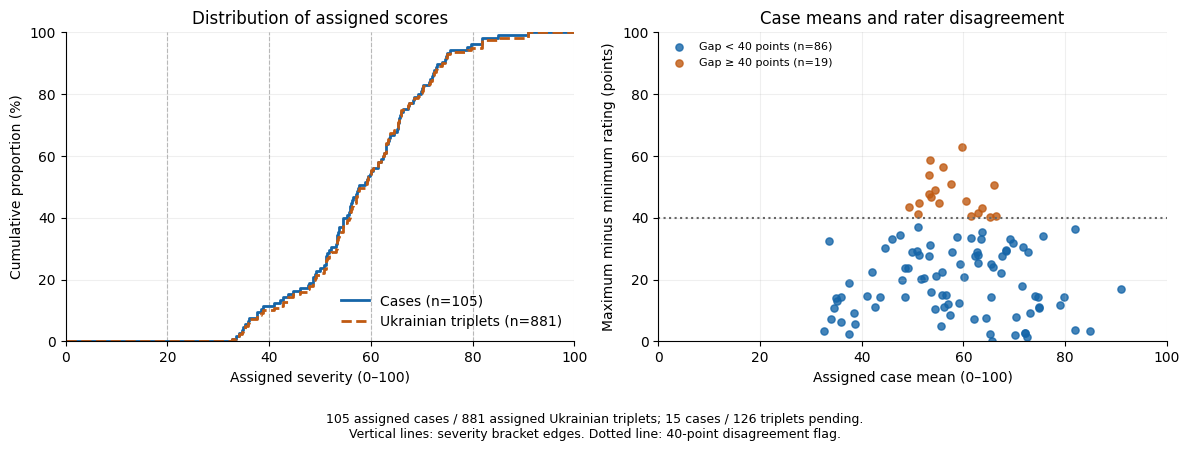

In [7]:
distribution = severity_distribution(taxonomy_with_severity, dataset["rows"]["uk"])
summary = distribution["summary"]
cdf_table = DataFrame(distribution["cdf"])
display(
    DataFrame(
        [
            {"Measure": label, "Value": value}
            for label, value in (
                ("Assigned cases", str(summary["assigned_cases"])),
                ("Pending cases", str(summary["pending_cases"])),
                ("Case-weighted mean", f"{summary['case_mean']:.2f}"),
                ("Case median", f"{summary['case_median']:.2f}"),
                ("Observed case range", f"{summary['case_min']:.2f}–{summary['case_max']:.2f}"),
                ("Assigned Ukrainian triplets", str(summary["assigned_triplets"])),
                ("Pending Ukrainian triplets", str(summary["pending_triplets"])),
                ("Triplet-weighted mean", f"{summary['triplet_weighted_mean']:.2f}"),
            )
        ]
    )
)
cdf_preview = cdf_table.iloc[:: max(1, len(cdf_table) // 8)].copy()
for column in ("case_fraction", "triplet_fraction"):
    cdf_preview[column] = (100 * cdf_preview[column]).round(2)
display(
    cdf_preview[
        [
            "severity_score",
            "cumulative_cases",
            "case_fraction",
            "cumulative_triplets",
            "triplet_fraction",
        ]
    ].rename(
        columns={
            "severity_score": "Score threshold",
            "cumulative_cases": "Cases ≤ threshold",
            "case_fraction": "Assigned cases (%)",
            "cumulative_triplets": "Ukrainian triplets ≤ threshold",
            "triplet_fraction": "Assigned Ukrainian triplets (%)",
        }
    )
)

case_bracket_counts = Counter(row["severity_bracket"] for row in taxonomy_with_severity)
unique_triplets = {row["id"]: row for row in triplet_severity["uk"]}
triplet_bracket_counts = Counter(row["severity_bracket"] for row in unique_triplets.values())
bracket_summary = []
cumulative_cases = cumulative_triplets = 0
for bracket in brackets:
    cases = case_bracket_counts[bracket["code"]]
    triplets = triplet_bracket_counts[bracket["code"]]
    cumulative_cases += cases
    cumulative_triplets += triplets
    bracket_summary.append(
        {
            **bracket,
            "case_count": cases,
            "triplet_count": triplets,
            "case_fraction": cases / summary["assigned_cases"],
            "triplet_fraction": triplets / summary["assigned_triplets"],
            "cumulative_cases": cumulative_cases,
            "cumulative_triplets": cumulative_triplets,
            "cumulative_case_fraction": cumulative_cases / summary["assigned_cases"],
            "cumulative_triplet_fraction": cumulative_triplets / summary["assigned_triplets"],
        }
    )
bracket_table = DataFrame(bracket_summary)
display(
    DataFrame(
        [
            {
                "Severity bracket": row["label"],
                "Assigned mean": interval_label(row),
                "Cases": f"{row['case_count']} ({100 * row['case_fraction']:.2f}%)",
                "Ukrainian triplets": f"{row['triplet_count']} ({100 * row['triplet_fraction']:.2f}%)",
                "Cases through bracket": f"{row['cumulative_cases']} ({100 * row['cumulative_case_fraction']:.2f}%)",
                "Ukrainian triplets through bracket": f"{row['cumulative_triplets']} ({100 * row['cumulative_triplet_fraction']:.2f}%)",
            }
            for row in bracket_summary
        ]
    )
)

figure_png = work / "severity-distribution.png"
figure_svg = work / "severity-distribution.svg"
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
gap_threshold = 100 * protocol["disagreement_threshold"]
if distribution["cdf"]:
    x = [0] + cdf_table["severity_score"].tolist() + [100]
    axes[0].step(
        x,
        [0] + (100 * cdf_table["case_fraction"]).tolist() + [100],
        where="post",
        linewidth=2,
        color="#1565A8",
        label=f"Cases (n={summary['assigned_cases']})",
    )
    axes[0].step(
        x,
        [0] + (100 * cdf_table["triplet_fraction"]).tolist() + [100],
        where="post",
        linewidth=2,
        linestyle="--",
        color="#C05A12",
        label=f"Ukrainian triplets (n={summary['assigned_triplets']})",
    )
axes[0].set(
    xlim=(0, 100),
    ylim=(0, 100),
    xlabel="Assigned severity (0–100)",
    ylabel="Cumulative proportion (%)",
    title="Distribution of assigned scores",
)
for bracket in brackets[1:]:
    axes[0].axvline(bracket["lower"], color="#BBBBBB", linestyle="--", linewidth=0.8, zorder=0)
axes[0].legend(loc="lower right", frameon=False)

for status, color, label in (
    ("aggregated", "#1565A8", f"Gap < {gap_threshold:g} points"),
    ("high_disagreement", "#C05A12", f"Gap ≥ {gap_threshold:g} points"),
):
    selected = [row for row in case_decision_rows if row["severity_status"] == status]
    axes[1].scatter(
        [row["severity_score"] for row in selected],
        [row["rating_gap_100"] for row in selected],
        s=27,
        alpha=0.8,
        color=color,
        label=f"{label} (n={len(selected)})",
    )
axes[1].axhline(gap_threshold, color="#666666", linestyle=":", linewidth=1.5)
axes[1].set(
    xlim=(0, 100),
    ylim=(0, 100),
    xlabel="Assigned case mean (0–100)",
    ylabel="Maximum minus minimum rating (points)",
    title="Case means and rater disagreement",
)
axes[1].legend(loc="upper left", frameon=False, fontsize=8)
for axis in axes:
    axis.grid(alpha=0.2)
    axis.spines[["top", "right"]].set_visible(False)
figure.tight_layout(rect=(0, 0.1, 1, 1))
figure.text(
    0.5,
    0.015,
    f"{summary['assigned_cases']} assigned cases / {summary['assigned_triplets']} assigned Ukrainian triplets; "
    f"{summary['pending_cases']} cases / {summary['pending_triplets']} triplets pending.\n"
    f"Vertical lines: severity bracket edges. Dotted line: {gap_threshold:g}-point disagreement flag.",
    ha="center",
    fontsize=9,
)
figure.savefig(figure_png, dpi=180, bbox_inches="tight")
figure.savefig(figure_svg, bbox_inches="tight", metadata={"Date": None, "Creator": "WarBias"})
display(figure)
plt.close(figure)

## Save the taxonomy and triplet sidecars

The taxonomy export preserves all case claims and source references and adds the
severity fields. JSONL retains null values and individual-rating records. The CSV
stores those rating records as JSON text. Triplet sidecars use the same IDs and
order as the Ukrainian and English data.

The decision audit shows the eligible scores and their arithmetic. The cumulative
table, bracket frequencies, descriptive summary and figure are exported for inspection.

In [8]:
taxonomy_csv = work / "taxonomy-severity.csv"
taxonomy_jsonl = work / "taxonomy-severity.jsonl"
csv_table = case_table.copy()
csv_table["severity_ratings"] = csv_table["severity_ratings"].map(canonical_json)
csv_table.to_csv(taxonomy_csv, index=False)
write_rows(taxonomy_jsonl, taxonomy_with_severity)
sidecar_paths = {}
for language, rows in triplet_severity.items():
    path = work / f"triplet-severity-{language}.jsonl"
    write_rows(path, rows)
    assert read_rows(path) == rows
    sidecar_paths[language] = path.as_posix()
assert read_rows(taxonomy_jsonl) == taxonomy_with_severity
decision_csv = work / "case-decisions.csv"
decision_jsonl = work / "case-decisions.jsonl"
decision_table = DataFrame(case_decision_rows)
for field in ("eligible_scores_100", "excluded_ratings"):
    decision_table[field] = decision_table[field].map(canonical_json)
decision_table.to_csv(decision_csv, index=False)
write_rows(decision_jsonl, case_decision_rows)
cdf_csv = work / "severity-cdf.csv"
cdf_table.to_csv(cdf_csv, index=False)
bracket_csv = work / "severity-brackets.csv"
bracket_table.to_csv(bracket_csv, index=False)
summary_json = work / "severity-summary.json"
write_json(summary_json, summary)
assert read_rows(decision_jsonl) == case_decision_rows
result = {
    "stage": "severity",
    "status": "assigned_from_case_annotations",
    "taxonomy_binding": taxonomy_binding,
    "scope": scope,
    "source_ratings": len(ratings),
    "current_case_ratings": len(current_ratings),
    "taxonomy_cases": len(taxonomy_with_severity),
    "assigned_cases": sum(row["severity_score"] is not None for row in taxonomy_with_severity),
    "pending_cases": sum(row["severity_score"] is None for row in taxonomy_with_severity),
    "case_status_counts": dict(case_status_counts),
    "triplets_per_language": {key: len(rows) for key, rows in triplet_severity.items()},
    "assigned_triplets_per_language": {
        key: sum(row["severity_score"] is not None for row in rows)
        for key, rows in triplet_severity.items()
    },
    "taxonomy_csv": taxonomy_csv.as_posix(),
    "taxonomy_jsonl": taxonomy_jsonl.as_posix(),
    "triplet_sidecars": sidecar_paths,
    "analysis": {
        "summary": summary,
        "case_decisions_csv": decision_csv.as_posix(),
        "case_decisions_jsonl": decision_jsonl.as_posix(),
        "cdf_csv": cdf_csv.as_posix(),
        "bracket_summary_csv": bracket_csv.as_posix(),
        "summary_json": summary_json.as_posix(),
        "figure_png": figure_png.as_posix(),
        "figure_svg": figure_svg.as_posix(),
    },
}
write_json(work / "severity-result.json", result)
result

{'stage': 'severity',
 'status': 'assigned_from_case_annotations',
 'taxonomy_binding': {'path': 'protocol/inputs/cohort_taxonomy.csv',
  'sha256': 'a97a1de753d2ac17b7f8c76e0f749ff34efcaf3e505d8c144987b114a5e33577'},
 'scope': {'taxonomy_cases': 120,
  'ratings': 239,
  'rating_cases_matched': 120,
  'rating_cases_unmatched': 0,
  'evidence_cases_matched': 120,
  'evidence_cases_unmatched': 0,
  'taxonomy_cases_without_ratings': 0,
  'taxonomy_cases_without_evidence': 0},
 'source_ratings': 239,
 'current_case_ratings': 239,
 'taxonomy_cases': 120,
 'assigned_cases': 105,
 'pending_cases': 15,
 'case_status_counts': {'high_disagreement': 19,
  'aggregated': 86,
  'insufficient_ratings': 15},
 'triplets_per_language': {'uk': 1007, 'en': 1007},
 'assigned_triplets_per_language': {'uk': 881, 'en': 881},
 'taxonomy_csv': 'runs/walkthrough/severity-scope-final/06_severity-udfar_2s/taxonomy-severity.csv',
 'taxonomy_jsonl': 'runs/walkthrough/severity-scope-final/06_severity-udfar_2s/taxonomy